# Traning A MNIST Dataset

In [8]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784' , as_frame=False)

X , y = mnist.data , mnist.target

print(X)
print(X.shape)
print("=" * 60)
print(y)
print(y.shape)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
(70000, 784)
['5' '0' '4' ... '4' '5' '6']
(70000,)


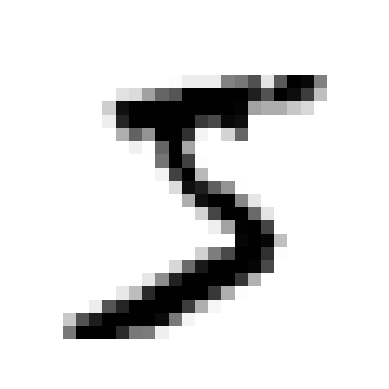

In [9]:
import matplotlib.pyplot as plt 

def plot_digit(image_data):
    image = image_data.reshape(28 , 28)
    plt.imshow(image , cmap="binary")
    plt.axis("off")


some_digit = X[0]
plot_digit(some_digit)
plt.show()

In [10]:
X_train , X_test = X[:6000] , X[6000:7000]
y_train , y_test = y[:6000] , y[6000:7000]

In [11]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state= 42,
    n_jobs=1
)

In [12]:
model.fit(X_train , y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [13]:
y_predict = model.predict(X_test)

In [14]:
print(y_predict)

['6' '0' '1' '1' '5' '2' '8' '3' '0' '4' '9' '5' '2' '6' '7' '7' '3' '8'
 '5' '9' '1' '1' '8' '0' '6' '4' '5' '5' '4' '6' '8' '6' '3' '3' '0' '4'
 '9' '4' '2' '2' '3' '8' '9' '1' '9' '0' '7' '6' '3' '4' '7' '9' '1' '7'
 '7' '2' '2' '3' '4' '3' '2' '9' '1' '2' '7' '0' '5' '9' '5' '3' '1' '3'
 '8' '9' '9' '1' '0' '5' '9' '2' '2' '3' '1' '1' '9' '6' '5' '7' '7' '3'
 '6' '7' '9' '8' '0' '4' '5' '0' '3' '2' '9' '4' '8' '0' '1' '2' '3' '4'
 '1' '7' '1' '8' '5' '0' '2' '7' '1' '0' '3' '6' '4' '9' '1' '3' '2' '2'
 '2' '4' '4' '8' '8' '6' '7' '0' '7' '1' '8' '0' '2' '6' '7' '7' '1' '2'
 '2' '9' '0' '7' '3' '9' '6' '5' '8' '8' '4' '9' '9' '6' '8' '6' '4' '2'
 '9' '8' '9' '1' '9' '7' '2' '5' '3' '5' '2' '7' '9' '3' '7' '5' '6' '0'
 '5' '1' '3' '1' '4' '3' '1' '8' '5' '4' '2' '9' '1' '4' '6' '5' '8' '1'
 '5' '8' '5' '6' '9' '8' '2' '9' '1' '0' '1' '1' '4' '2' '2' '3' '8' '4'
 '3' '5' '4' '6' '4' '7' '2' '8' '7' '9' '1' '0' '0' '1' '5' '2' '1' '3'
 '9' '4' '6' '5' '9' '6' '8' '7' '8' '8' '1' '0' '6

In [15]:
from sklearn.metrics import accuracy_score , classification_report
accuracy = accuracy_score(y_test, y_predict)
print(accuracy)

0.943


In [16]:
print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy *100 , "%")
print(classification_report(y_test, y_predict))

Accuracy: 0.943
Accuracy percentage: 94.3 %
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        99
           1       0.98      0.98      0.98       113
           2       0.93      0.97      0.95        94
           3       0.96      0.89      0.92       108
           4       0.94      0.94      0.94        93
           5       0.95      0.97      0.96        96
           6       0.96      0.97      0.97       101
           7       0.96      0.89      0.92       103
           8       0.95      0.89      0.92        99
           9       0.84      0.94      0.88        94

    accuracy                           0.94      1000
   macro avg       0.94      0.94      0.94      1000
weighted avg       0.94      0.94      0.94      1000



In [17]:
import numpy as np
import matplotlib.pyplot as plt

In [18]:
wrong_indices = np.where(y_predict != y_test)[0]
print("Incorrect predictions:", len(wrong_indices))

Incorrect predictions: 57


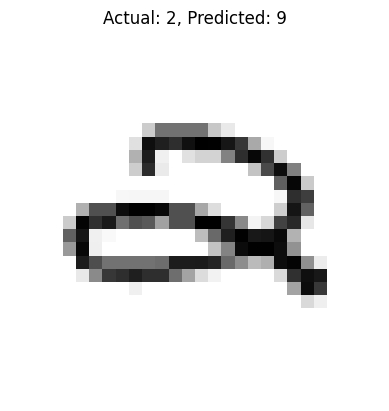

In [19]:
if len(wrong_indices) > 0:
    i = wrong_indices[0]

    plt.imshow(X_test[i].reshape(28, 28), cmap="binary")
    plt.title(f"Actual: {y_test[i]}, Predicted: {y_predict[i]}")
    plt.axis("off")
    plt.show()